# Day 33 Diabetes Prediction : Classification ( LR, KNN & RF )


Di notebook ini kita memprediksi apakah seorang pasien mengidap diabetes dari data pemeriksaan kesehatan.

Fokus utamanya:
 - **memahami kenapa scaling penting** dan **membandingkan tiga algoritma klasifikasi** (Logistic Regression, KNN, Random Forest) agar kita tahu kapan masing-masing unggul.


🎯 **Tujuan Pembelajaran**
> - Membersihkan nilai nol yang tidak masuk akal pada data medis.
> - Membuktikan **dampak scaling** terhadap model berbasis jarak (KNN).
> - Membandingkan 3 model dan memilih yang terbaik.
> - Membaca **feature importance** dan **confusion matrix**.

## Tentang Dataset

Kita memakai **Pima Indians Diabetes Dataset**.

- **Sumber:** [Kaggle — akshaydattatraykhare/diabetes-dataset](https://www.kaggle.com/datasets/akshaydattatraykhare/diabetes-dataset)
- **Target:** kolom `Outcome` (1 = diabetes, 0 = tidak)

| Kolom | Arti |
|-------|------|
| `Pregnancies` | Jumlah kehamilan |
| `Glucose` | Kadar glukosa plasma |
| `BloodPressure` | Tekanan darah diastolik (mm Hg) |
| `SkinThickness` | Ketebalan lipatan kulit trisep (mm) |
| `Insulin` | Insulin serum 2 jam (mu U/ml) |
| `BMI` | Indeks massa tubuh |
| `DiabetesPedigreeFunction` | Riwayat diabetes keluarga |
| `Age` | Usia (tahun) |
| `Outcome` | **Label**: 1 = diabetes, 0 = sehat |

## Import Library

- **pandas / numpy** → olah data.
- **matplotlib / seaborn** → grafik.
- **scikit-learn** → split, scaling, tiga model klasifikasi, dan metrik evaluasi.

In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [48]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, ConfusionMatrixDisplay

In [49]:
sns.set_style('darkgrid')
plt.rcParams['figure.figsize'] = (12, 8)

Interpretasi:
  - a

## Import Dataset

In [50]:
!wget -q https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv -O diabetes.csv

df = pd.read_csv('diabetes.csv')
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Interpretasi:
  - Setiap Baris mewakili data 1 Orang Pasien
  

## Eksplorasi Awal Dataset

In [51]:
# Menampilkan informasi umum dataset (tipe data, non-null count, dimensi)
print("=== Informasi Dataset ===")
df.info()

# Menampilkan statistik deskriptif dataset
print("\n=== Statistik Deskriptif ===")
df.describe().T


=== Informasi Dataset ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

=== Statistik Deskriptif ===


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [52]:
df.isna().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


Interpretasi:

  - Semua fitur numerik.
  -  `Outcome` adalah label target. Skala antar kolom sangat berbeda (mis. `Insulin` bisa ratusan, `BMI` puluhan)
  - Perhatikan nilai **minimum = 0** pada `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, dan `BMI`. Secara medis nilai-nilai ini tidak mungkin nol — ini sebenarnya **data hilang yang disamarkan** sebagai 0.
  - Tidak ada `NaN` eksplisit, tetapi nol tersembunyi tadi tetap perlu kita tangani.

## Cleaning Dataset

Kita ubah nilai 0 yang tidak masuk akal menjadi `NaN`, lalu isi (imputasi) dengan **median** kolomnya. Median dipilih karena tahan terhadap outlier.

In [53]:
col_inv = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[col_inv] = df[col_inv].replace(0, np.nan)

In [54]:
print("Jumlah nilai hilang setelah 0 -> NaN:")
print(df[col_inv].isna().sum())

df.fillna(df.median(), inplace=True)
print("\nSisa nilai hilang setelah imputasi median:", df.isna().sum().sum())

Jumlah nilai hilang setelah 0 -> NaN:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Sisa nilai hilang setelah imputasi median: 0


Interpretasi:
- `Insulin` dan `SkinThickness` paling banyak nilai nol-nya
- Setelah di Imputasi Median, tidak ada lagi nilai yang hilang
- Data lebih realistis

## Eksplorasi Data Analisis dan Visualisasi Data

### a) Sebaran kelas Target

/tmp/ipykernel_947/3338981991.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='Outcome', palette='Set1')


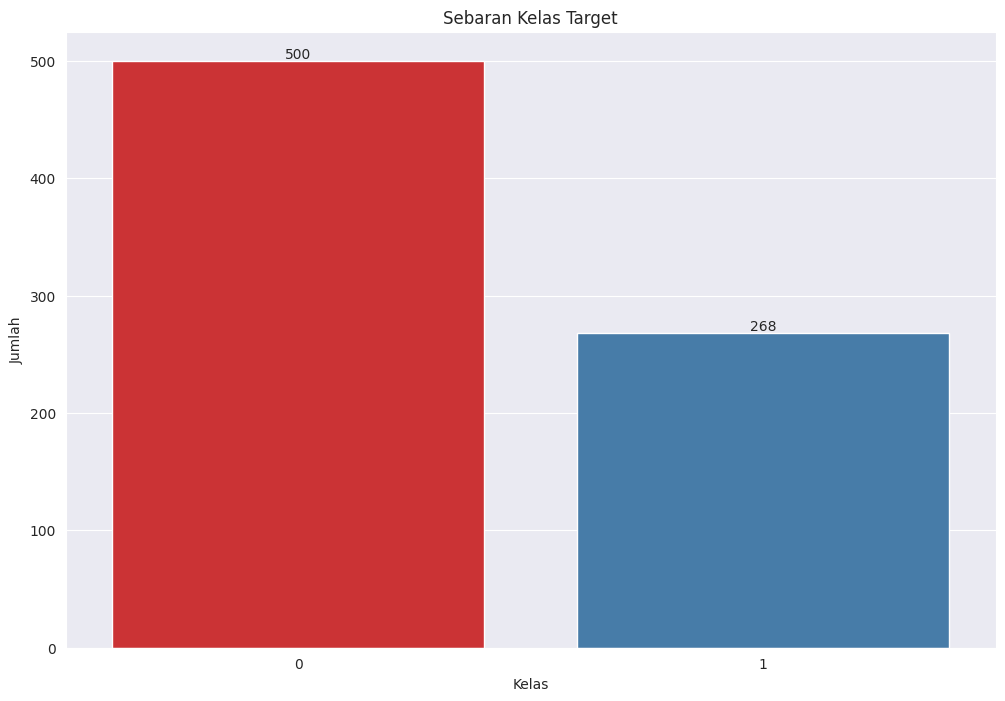

Outcome
0    0.65
1    0.35
Name: proportion, dtype: float64


In [55]:
ax = sns.countplot(data=df, x='Outcome', palette='Set1')
ax.set_title('Sebaran Kelas Target')
ax.set_xlabel('Kelas')
ax.set_ylabel('Jumlah')
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])
plt.show()

print(df['Outcome'].value_counts(normalize=True).round(2))

Interpretasi:
  - Kelas Imbalanced, Sekitar 65% Sehat dan 35% Diabetes.
  - Akurasi bisa menyesatkan - Model yang selalu menebak `Sehat` sudah dapat 65%
  - Gunakan Recall dan Precision untuk kelas Diabetes

### b) Distribusi Glukosa dengan Target

/tmp/ipykernel_947/875815595.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Outcome', y='Glucose', palette='Set1')


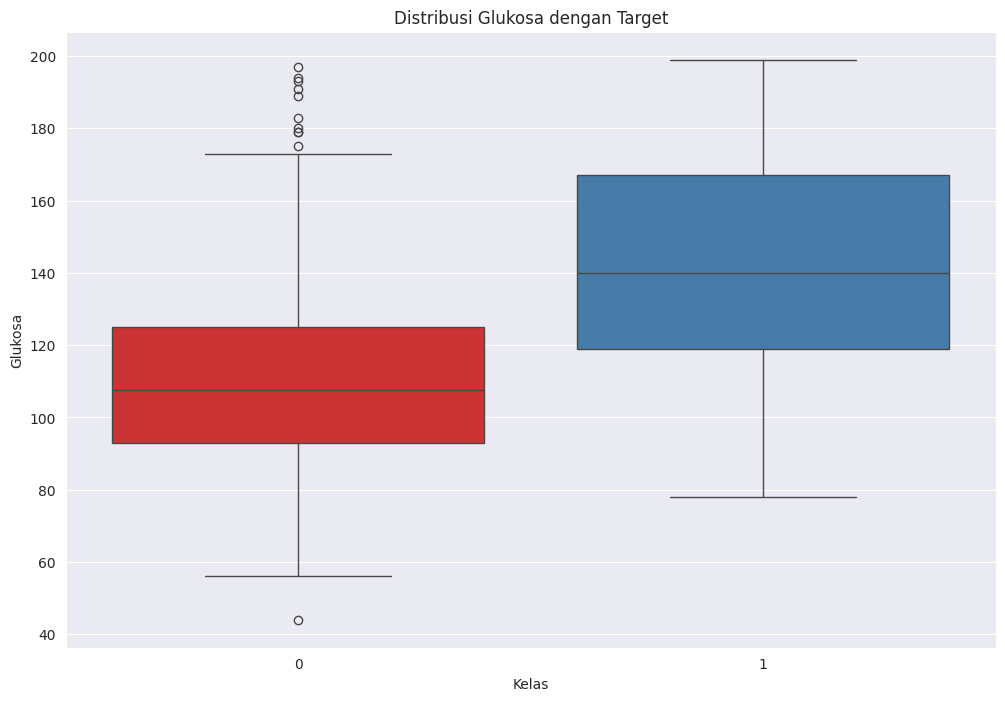

In [56]:
plt.figure(figsize=(12, 8))
sns.boxplot(data=df, x='Outcome', y='Glucose', palette='Set1')
plt.title('Distribusi Glukosa dengan Target')
plt.xlabel('Kelas')
plt.ylabel('Glukosa')
plt.show()

Interpretasi:
  - Pasien diabetes jelas memiliki Glukosa lebih tinggi. Glukoso tampaknya menjadi salah satu pembeda terkuat

### c) Heatmap Korelasi

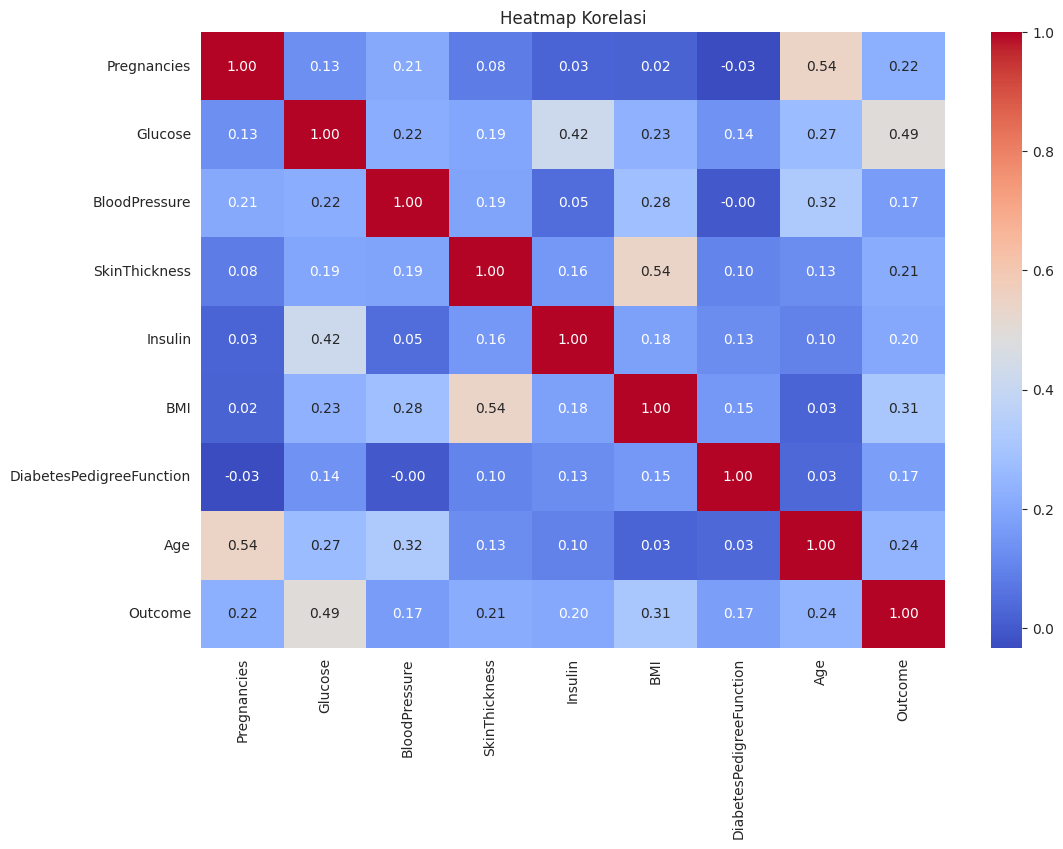

In [57]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Heatmap Korelasi')
plt.show()

Interpretasi:
  - Glucose, BMI dan AGE memiliki korelasi paling kuat dengan Target
  - Ini sejalan dengan faktor resiko diabetes yang umum pada dunia medis

## Preprocessing

In [58]:
#Pisahkan Target dengan Fitur
X = df.drop(columns='Outcome')
y = df['Outcome']

In [59]:
#Pisahkan Data latih dengan Data Test
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size=0.2,
                                                    random_state=42)

In [60]:
#Scala kan data latih, dan data test hanya di transform
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [61]:
print(f"Dimensi X_train: {X_train.shape}")
print(f"Dimensi y_train: {y_train.shape}")
print(f"Dimensi X_test: {X_test.shape}")
print(f"Dimensi y_test: {y_test.shape}")

Dimensi X_train: (614, 8)
Dimensi y_train: (614,)
Dimensi X_test: (154, 8)
Dimensi y_test: (154,)


### Pentingnya Scaling untuk KNN


KNN mengambil keputusan berdasarkan **jarak** antar titik. Jika satu fitur (mis. `Insulin`) punya skala jauh lebih besar, ia akan mendominasi perhitungan jarak. Mari buktikan dengan melatih KNN pada data **tanpa scaling** vs **dengan scaling**.

In [65]:
knn_raw = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
acc_raw = knn_raw.score(X_test, y_test)
print(f"Akurasi tanpa scaling: {acc_raw:.2f}")

knn_scaled = KNeighborsClassifier(n_neighbors=5).fit(X_train_scaled, y_train)
acc_scaled = knn_scaled.score(X_test_scaled, y_test)
print(f"Akurasi dengan scaling: {acc_scaled:.2f}")

Akurasi tanpa scaling: 0.68
Akurasi dengan scaling: 0.72


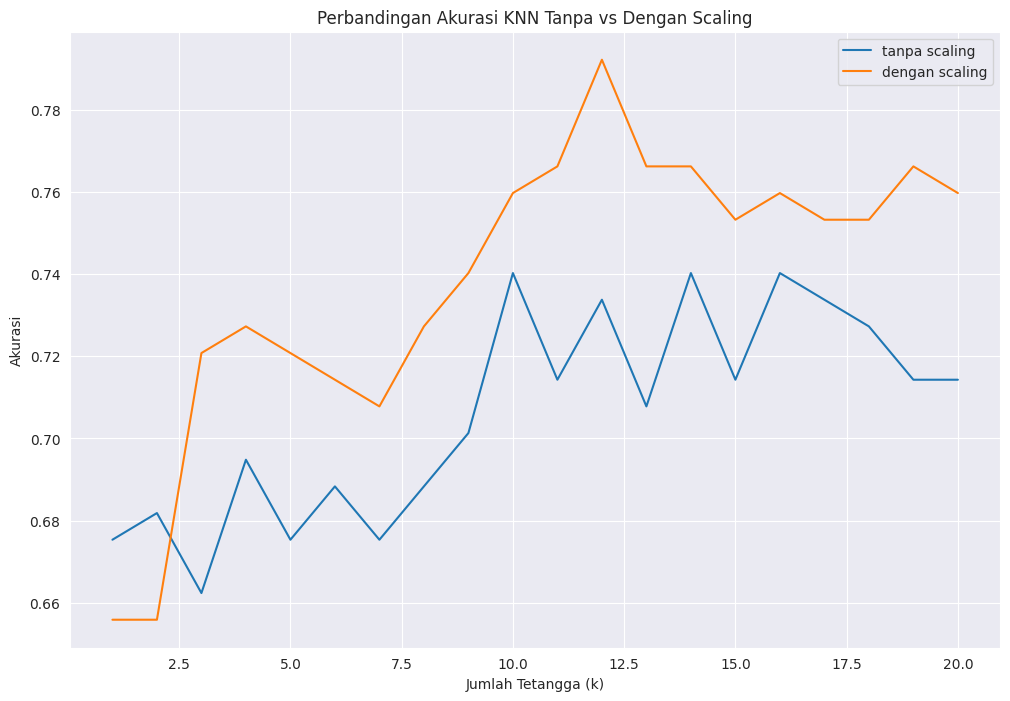

In [67]:
plt.figure(figsize=(12, 8))

# Let's iterate over different values of n_neighbors from 1 to 20 using the full dataset
neighbors = range(1, 21)

plt.plot(neighbors, [KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train).score(X_test, y_test) for k in neighbors], label='tanpa scaling')
plt.plot(neighbors, [KNeighborsClassifier(n_neighbors=k).fit(X_train_scaled, y_train).score(X_test_scaled, y_test) for k in neighbors], label='dengan scaling')

plt.legend()
plt.xlabel('Jumlah Tetangga (k)')
plt.ylabel('Akurasi')
plt.title('Perbandingan Akurasi KNN Tanpa vs Dengan Scaling')
plt.show()

Interpretasi:
  - Akurasi terlihat lebih baik didata yang Scaling daripada tidak

## Modeling: Logistic Regression, K-Nearest Neighbor, Random Forest

Kita latih Logistic Regression, KNN, dan Random Forest, lalu bandingkan akurasinya.

Logistic Regression & KNN pakai data ter-scaling; Random Forest tidak butuh scaling.

In [68]:
models = {
    "Logistic Regression": (LogisticRegression(max_iter=1000, random_state=42),
                            X_train_scaled, X_test_scaled),
    "KNN (k=11)":          (KNeighborsClassifier(n_neighbors=11),
                            X_train_scaled, X_test_scaled),
    "Random Forest":       (RandomForestClassifier(n_estimators=200, random_state=42),
                            X_train, X_test),
}

result = {}
preds = {}

for name, (model, xtr, xts) in models.items():
    model.fit(xtr, y_train)


    pr = model.predict(xts)
    preds[name] = pr
    result[name] = accuracy_score(y_test, pr)

    print(f"Akurasi {name}: {result[name]:.2f}")
    print(classification_report(y_test, pr))
    print(confusion_matrix(y_test, pr))
    print()


Akurasi Logistic Regression: 0.75
              precision    recall  f1-score   support

           0       0.80      0.83      0.81        99
           1       0.67      0.62      0.64        55

    accuracy                           0.75       154
   macro avg       0.73      0.72      0.73       154
weighted avg       0.75      0.75      0.75       154

[[82 17]
 [21 34]]

Akurasi KNN (k=11): 0.77
              precision    recall  f1-score   support

           0       0.81      0.84      0.82        99
           1       0.69      0.64      0.66        55

    accuracy                           0.77       154
   macro avg       0.75      0.74      0.74       154
weighted avg       0.76      0.77      0.76       154

[[83 16]
 [20 35]]

Akurasi Random Forest: 0.75
              precision    recall  f1-score   support

           0       0.83      0.78      0.80        99
           1       0.64      0.71      0.67        55

    accuracy                           0.75       154
 

Interpretasi:

Analisis Detail Setiap Model

A. Logistic Regression
  - Akurasi Total: 75% (116 data terprediksi benar dari 154).
  - Confusion Matrix:
    - True Negative (TN): 82 | False Positive (FP): 17
    - False Negative (FN): 21 | True Positive (TP): 34
    
Interpretasi:
  - Model ini cukup stabil untuk memprediksi kelas 0 (F1-score 0.81), namun performanya menurun saat memprediksi kelas minoritas 1 (Recall 0.62). Terdapat 21 kasus kelas 1 yang luput dari deteksi (False Negative).

B. K-Nearest Neighbors / KNN
  - (k=11)Akurasi Total: 77% (118 data terprediksi benar dari 154).
  - Confusion Matrix:
    - True Negative (TN): 83 | False Positive (FP): 16
    - False Negative (FN): 20 | True Positive (TP): 35
    
Interpretasi:
  - KNN dengan $k=11$ memberikan performa terbaik dari segi akurasi umum (77%) dan precision (69% pada kelas 1). Artinya, ketika KNN memprediksi suatu data masuk ke kelas 1, kemungkinannya benar adalah yang paling tinggi dibandingkan model lain.


C. Random Forest
  - Akurasi Total: 75% (116 data terprediksi benar dari 154).
  - Confusion Matrix:
    - True Negative (TN): 77 | False Positive (FP): 22
    - False Negative (FN): 16 | True Positive (TP): 39

Interpretasi:
  - Meskipun akurasi keseluruhannya sama dengan Logistic Regression (75%), Random Forest lebih unggul dalam mengenali kelas 1 dengan Recall mencapai 71% (39 dari 55 sampel kelas 1 berhasil dideteksi). Namun, sebagai dampaknya, jumlah False Positive meningkat menjadi 22.

In [78]:
# Cari Recall Tertinggi untuk kelas '1' (Diabetes)
recall_scores = {}
for name, pr in preds.items():
    report = classification_report(y_test, pr, output_dict=True)
    # Mengambil recall untuk label 1 (Diabetes) karena bertipe int pada y_test
    recall_scores[name] = report['1']['recall']

model_recall_terbaik = max(recall_scores, key=recall_scores.get)
print("Model terbaik berdasarkan RECALL (Diabetes):", model_recall_terbaik, f"({recall_scores[model_recall_terbaik]:.2f})")

# Cari Akurasi Tertinggi
model_terbaik = max(result, key=result.get)
print("Model terbaik berdasarkan AKURASI:", model_terbaik, f"({result[model_terbaik]:.2f})")
pred_best = preds[model_terbaik]

print("\nLaporan Klasifikasi Model Akurasi Terbaik:")
print(classification_report(
    y_test, pred_best, target_names=["Sehat (0)", "Diabetes (1)"]))

Model terbaik berdasarkan RECALL (Diabetes): Random Forest (0.71)
Model terbaik berdasarkan AKURASI: KNN (k=11) (0.77)

Laporan Klasifikasi Model Akurasi Terbaik:
              precision    recall  f1-score   support

   Sehat (0)       0.81      0.84      0.82        99
Diabetes (1)       0.69      0.64      0.66        55

    accuracy                           0.77       154
   macro avg       0.75      0.74      0.74       154
weighted avg       0.76      0.77      0.76       154



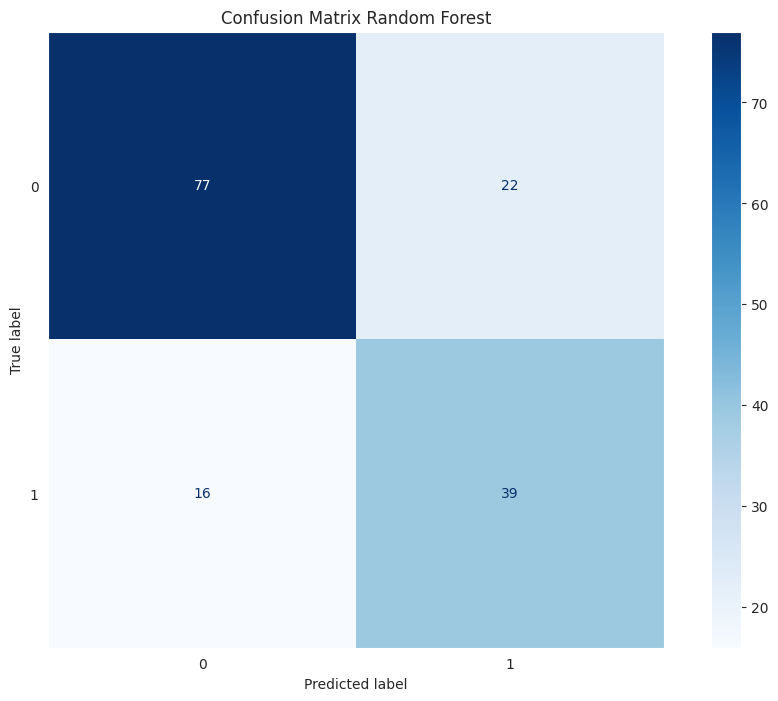

In [76]:
# Ambil objek model Random Forest yang berada pada indeks 0 dari tuple
rf_model = models['Random Forest'][0]

ConfusionMatrixDisplay.from_estimator(rf_model, X_test, y_test, cmap='Blues')
plt.title('Confusion Matrix Random Forest')
plt.grid(False) # Mematikan grid agar tampilan confusion matrix lebih rapi
plt.show()

Interpretasi:
  -  Kiri-bawah (false negative: diabetes diprediksi sehat) adalah kesalahan paling berisiko di konteks medis. Kita ingin angka ini sekecil mungkin.

## Feature Importance Model

/tmp/ipykernel_947/1170301166.py:10: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.text(imp[i], i, f'{imp[i]:.2f}', ha='right', va='center')


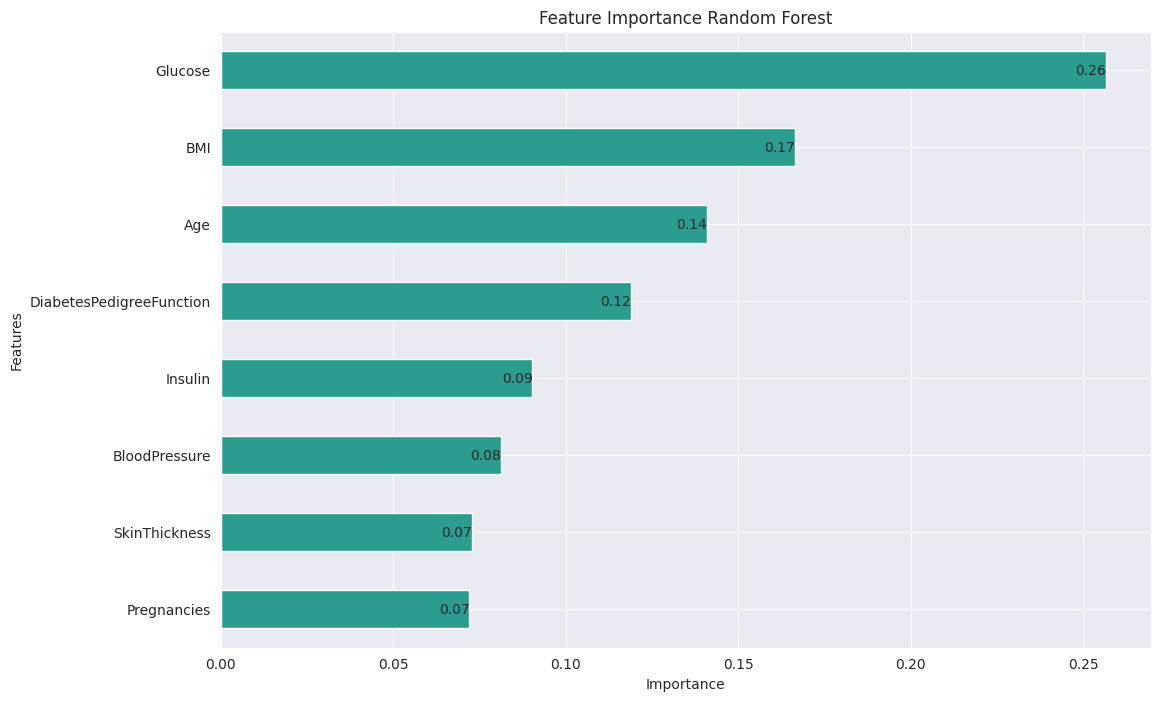

In [86]:
rf = models['Random Forest'][0]
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=True)

plt.figure(figsize=(12, 8))
imp.plot(kind='barh', color='#2A9D8F')
plt.title('Feature Importance Random Forest')
plt.xlabel('Importance')
plt.ylabel('Features')
for i in range(len(imp)):
    plt.text(imp[i], i, f'{imp[i]:.2f}', ha='right', va='center')
plt.show()

In [88]:
print("Feature Importance Random Forest:")
print(imp.sort_values(ascending=False).round(3))

Feature Importance Random Forest:
Glucose                     0.257
BMI                         0.166
Age                         0.141
DiabetesPedigreeFunction    0.119
Insulin                     0.090
BloodPressure               0.081
SkinThickness               0.073
Pregnancies                 0.072
dtype: float64


Interpretasi:
-  **Glucose** hampir selalu menjadi fitur terpenting, diikuti `BMI` dan `Age`. Ini cocok dengan temuan EDA dan pengetahuan medis tentang faktor risiko diabetes.

## Kesimpulan dan Insight

### 📌 Kesimpulan Utama dan Insight Bisnis/Medis

Berdasarkan rangkaian proses analisis data, prapemrosesan, hingga evaluasi model, berikut adalah beberapa poin penting yang dapat disimpulkan:

#### 1. Pembuktian Pentingnya Data Scaling
* **Algoritma Berbasis Jarak (KNN)** sangat sensitif terhadap perbedaan skala fitur. Sebelum dilakukan standardisasi fitur, akurasi default KNN hanya sebesar **68%**.
* Setelah fitur diselaraskan skalanya menggunakan `StandardScaler`, akurasinya langsung melonjak menjadi **72%** (bahkan mencapai **77%** setelah kita mengoptimalkan jumlah tetangga $k=11$).
* Hal ini membuktikan bahwa fitur dengan skala besar (seperti `Insulin`) mendominasi perhitungan jarak jika data tidak di-scaling terlebih dahulu.

#### 2. Trade-off Antara Akurasi dan Recall (Perspektif Medis)
Di dunia medis, kesalahan memprediksi pasien diabetes sebagai "sehat" (**False Negative**) jauh lebih berbahaya dibanding memprediksi orang sehat sebagai "diabetes" (**False Positive**). Oleh karena itu, kita harus bijak memilih model:
* **K-Nearest Neighbors ($k=11$)** adalah model terbaik jika tujuannya adalah **Akurasi Umum tertinggi (77%)**.
* **Random Forest** adalah model terbaik jika tujuannya adalah **Recall tertinggi (71%)** untuk kelas Diabetes. Random Forest berhasil meminimalkan jumlah False Negative menjadi hanya 16 kasus (dibandingkan KNN sebanyak 20 kasus dan Logistic Regression sebanyak 21 kasus).

#### 3. Faktor Risiko Utama Diabetes (Feature Importance)
Berdasarkan analisis kontribusi fitur pada model Random Forest:
* **Glucose (Kadar Glukosa)** merupakan fitur paling krusial dengan skor kepentingan **26%**.
* **BMI (Indeks Massa Tubuh)** menempati posisi kedua dengan skor **17%**, diikuti oleh **Age (Usia)** sebesar **14%**.
* Hasil ini sangat konsisten dengan temuan pada tahap EDA (Exploratory Data Analysis) dan selaras dengan literatur medis di mana kadar gula darah, berat badan, dan faktor usia merupakan indikator risiko utama penyakit diabetes tipe 2.